# BCI-I × IDUN EEG Analysis Challenge — 1D CNN with leave-one-subject-out CV

Single-channel EEG epochs (7501 samples) are classified into 7 marker classes.
Subjects S001–S003 are labeled and S004 is the test subject.
Each fold holds out one labeled subject, and the three fold models are ensembled on S004 (soft and hard voting).

> The training and inference outputs below are from the original Colab run (CPU). The code has since been
> cleaned up (see the repo README), so re-running prints slightly different log lines.

In [ ]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.optim as optim
from scipy.stats import mode
from sklearn.metrics import balanced_accuracy_score, f1_score
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
from transformers import get_cosine_schedule_with_warmup

DATA_DIR = 'data'
SUBJECTS = ['S001', 'S002', 'S003']
device = 'cuda' if torch.cuda.is_available() else 'cpu'

## Data download

In [ ]:
!mkdir -p data
!gdown 17hi4uVml6QxmlwMLRj0EgaweYOUb4j2M -O data/bci-i-idun-eeg-analysis-challenge.zip
!unzip -oq data/bci-i-idun-eeg-analysis-challenge.zip -d data

## Data loading and augmentation

In [ ]:
class TimeSeriesAugmentation:
    def __init__(self, noise_level=0.05, shift_range=10):
        self.noise_level = noise_level
        self.shift_range = shift_range

    def add_noise(self, x):
        noise = torch.randn_like(x) * self.noise_level
        return x + noise

    def time_shift(self, x):
        # Generate random shift value
        shift = torch.randint(-self.shift_range, self.shift_range + 1, (1,)).item()
        # Roll the tensor along the time dimension
        return torch.roll(x, shifts=shift, dims=0)

    def scale(self, x):
        scale_factor = torch.rand(1) * 0.4 + 0.8  # Random scale between 0.8 and 1.2
        return x * scale_factor

class AugmentedDataset(Dataset):
    def __init__(self, X, y, augment=True):
        self.X = X
        self.y = y
        self.augment = augment
        self.aug = TimeSeriesAugmentation()

    def __getitem__(self, idx):
        x = self.X[idx].clone()  # Create a copy to avoid modifying original data
        if self.augment:
            if torch.rand(1) < 0.5:
                x = self.aug.add_noise(x)
            if torch.rand(1) < 0.5:
                x = self.aug.time_shift(x)
            if torch.rand(1) < 0.5:
                x = self.aug.scale(x)
        return x, self.y[idx]

    def __len__(self):
        return len(self.X)

In [ ]:
def load_data(data_dir=DATA_DIR):
    Xs = [np.load(f'{data_dir}/{s}_X.npy') for s in SUBJECTS]
    ys = [np.load(f'{data_dir}/{s}_y.npy') for s in SUBJECTS]
    X_test = np.load(f'{data_dir}/S004_X.npy')
    X_train, y_train = np.concatenate(Xs), np.concatenate(ys)

    # normalization stats include the unlabeled test subject (transductive)
    X_all = np.concatenate([X_train, X_test])
    mean_, std_ = X_all.mean(), X_all.std()

    markers = sorted(set(y_train))
    y_train = np.array([markers.index(m) for m in y_train])
    subject_ids = np.concatenate([np.full(len(x), i) for i, x in enumerate(Xs)])
    return (X_train - mean_) / std_, y_train, (X_test - mean_) / std_, subject_ids, markers


def create_dataloaders(batch_size=32, n_fold=0, num_workers=2):
    # leave-one-subject-out: fold i validates on SUBJECTS[i]
    X_train, y_train, _, subject_ids, _ = load_data()
    val_mask = subject_ids == n_fold

    train_dataset = AugmentedDataset(torch.FloatTensor(X_train[~val_mask]), torch.LongTensor(y_train[~val_mask]))
    val_dataset = AugmentedDataset(torch.FloatTensor(X_train[val_mask]), torch.LongTensor(y_train[val_mask]), augment=False)
    print(f'Fold {n_fold} (val = {SUBJECTS[n_fold]}): {len(train_dataset)} train / {len(val_dataset)} val')

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
    return train_loader, val_loader

## Training utilities

In [ ]:
def train_one_epoch(model, train_loader, criterion, optimizer, scheduler, device):
    model.train()
    running_loss = 0.0
    for images, labels in tqdm(train_loader):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimization step
        loss.backward()
        optimizer.step()
        scheduler.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    return epoch_loss

def validate(model, val_loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_labels = []
    all_outputs = []

    with torch.no_grad():
        for images, labels in tqdm(val_loader):
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            all_labels.append(labels.cpu().numpy())
            all_outputs.append(outputs.cpu().numpy())

    epoch_loss = running_loss / len(val_loader.dataset)

    all_labels = np.concatenate(all_labels)
    all_outputs = np.concatenate(all_outputs)
    all_outputs = torch.nn.functional.softmax(torch.tensor(all_outputs), dim=-1).numpy()  # Convert logits to probabilities

    return epoch_loss, all_labels, all_outputs

In [ ]:
class EarlyStopping:
    """Saves a checkpoint whenever the monitored score (higher is better) improves."""

    def __init__(self, patience=7, verbose=False, delta=0):
        self.patience = patience
        self.verbose = verbose
        self.delta = delta
        self.counter = 0
        self.best_score = -np.inf
        self.early_stop = False

    def __call__(self, score, model, path):
        if score >= self.best_score + self.delta:
            if self.verbose:
                print(f'Val score improved ({self.best_score:.4f} --> {score:.4f}). Saving model ...')
            self.best_score = score
            torch.save(model.state_dict(), os.path.join(path, 'checkpoint.pth'))
            self.counter = 0
        else:
            self.counter += 1
            print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True

In [ ]:
def train_model(model, model_name, num_epochs=10, batch_size=32, lr=1e-4, n_fold=0, device='cpu',
                patience=3, warmup_epochs=0, monitor='weighted_f1'):
    train_loader, val_loader = create_dataloaders(batch_size=batch_size, n_fold=n_fold)
    steps_per_epoch = len(train_loader)

    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = get_cosine_schedule_with_warmup(optimizer, steps_per_epoch * warmup_epochs, steps_per_epoch * num_epochs)
    early_stopping = EarlyStopping(patience=patience, verbose=True)

    path = model_name + str(n_fold)
    os.makedirs(path, exist_ok=True)
    train_losses, val_losses = [], []

    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer, scheduler, device)
        val_loss, val_labels, val_outputs = validate(model, val_loader, criterion, device)
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        val_preds = val_outputs.argmax(axis=-1)
        metrics = {
            'balanced_acc': balanced_accuracy_score(val_labels, val_preds),
            'weighted_f1': f1_score(val_labels, val_preds, average='weighted'),
            'macro_f1': f1_score(val_labels, val_preds, average='macro'),
        }
        print(f"Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Val Bal. Acc: {metrics['balanced_acc']:.4f}, "
              f"Val Weighted F1: {metrics['weighted_f1']:.4f}, Val Macro F1: {metrics['macro_f1']:.4f}")

        early_stopping(metrics[monitor], model, path)
        if early_stopping.early_stop:
            print('Early stopping')
            break
        print(f'Learning rate: {scheduler.get_last_lr()[0]:.2e}')

    os.makedirs('results', exist_ok=True)
    plt.figure()
    plt.plot(train_losses, label='Train Loss')
    plt.plot(val_losses, label='Validation Loss')
    plt.title(f'Fold {n_fold} (val = {SUBJECTS[n_fold]})')
    plt.xlabel('Epoch')
    plt.legend()
    plt.savefig(f'results/loss_fold{n_fold}.png')
    plt.show()

## Model

In [ ]:
class TimeSeriesCNN(nn.Module):
    def __init__(self, input_length, num_classes=7):
        super(TimeSeriesCNN, self).__init__()

        # Convolutional layers
        self.conv_layers = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=8, stride=1, padding='same'),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.MaxPool1d(kernel_size=2, stride=2),

            nn.Conv1d(32, 64, kernel_size=5, stride=1, padding='same'),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.MaxPool1d(kernel_size=2, stride=2),

            nn.Conv1d(64, 128, kernel_size=3, stride=1, padding='same'),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.MaxPool1d(kernel_size=2, stride=2)
        )

        # Calculate the size of flattened features
        self.flatten_size = self._get_flatten_size(input_length)

        # Fully connected layers
        self.fc_layers = nn.Sequential(
            nn.Linear(self.flatten_size, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def _get_flatten_size(self, input_length):
        # Helper function to calculate flattened size
        x = torch.randn(1, 1, input_length)
        x = self.conv_layers(x)
        return x.shape[1] * x.shape[2]

    def forward(self, x):
        # x shape: (batch_size, n_samples)
        # Add channel dimension
        x = x.unsqueeze(1)  # (batch_size, 1, n_samples)

        x = self.conv_layers(x)
        x = x.view(x.size(0), -1)  # Flatten
        x = self.fc_layers(x)
        return x

## Training (3 folds, leave-one-subject-out)

1887
655
Epoch 1/28


Train Loss: 1.6066, Val Loss: 1.5941, Val Accuracy: 0.1430, Val F1 : 0.1595
Validation loss decreased (inf --> -0.159509).  Saving model ...
Updating learning rate to 0.0002
Epoch 2/28


Train Loss: 1.3971, Val Loss: 1.5155, Val Accuracy: 0.1445, Val F1 : 0.1719
Validation loss decreased (-0.159509 --> -0.171907).  Saving model ...
Updating learning rate to 0.0004
Epoch 3/28


Train Loss: 1.3230, Val Loss: 1.5164, Val Accuracy: 0.1720, Val F1 : 0.2412
Validation loss decreased (-0.171907 --> -0.241167).  Saving model ...
Updating learning rate to 0.0006
Epoch 4/28


Train Loss: 1.2962, Val Loss: 1.5377, Val Accuracy: 0.2569, Val F1 : 0.2354
EarlyStopping counter: 1 out of 10
Updating learning rate to 0.0008
Epoch 5/28


Train Loss: 1.2548, Val Loss: 1.6127, Val Accuracy: 0.2139, Val F1 : 0.2798
Validation loss decreased (-0.241167 --> -0.279784).  Saving model ...
Updating learning rate to 0.001
Epoch 6/28


... (19 outputs left out)

Train Loss: 0.3668, Val Loss: 2.6033, Val Accuracy: 0.2740, Val F1 : 0.4190
EarlyStopping counter: 4 out of 10
Updating learning rate to 4.139434924727359e-05
Epoch 26/28


Train Loss: 0.3652, Val Loss: 2.6166, Val Accuracy: 0.2751, Val F1 : 0.4212
EarlyStopping counter: 5 out of 10
Updating learning rate to 1.8541356326100432e-05
Epoch 27/28


Train Loss: 0.3708, Val Loss: 2.6227, Val Accuracy: 0.2729, Val F1 : 0.4169
EarlyStopping counter: 6 out of 10
Updating learning rate to 4.657026981834622e-06
Epoch 28/28


Train Loss: 0.3601, Val Loss: 2.6226, Val Accuracy: 0.2729, Val F1 : 0.4169
EarlyStopping counter: 7 out of 10
Updating learning rate to 0.0


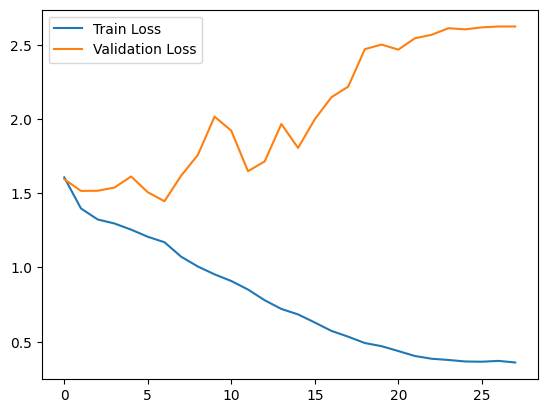

1478
1064
Epoch 1/28


Train Loss: 1.7019, Val Loss: 1.2743, Val Accuracy: 0.1668, Val F1 : 0.0813
Validation loss decreased (inf --> -0.081267).  Saving model ...
Updating learning rate to 0.0002
Epoch 2/28


Train Loss: 1.4976, Val Loss: 1.5957, Val Accuracy: 0.1976, Val F1 : 0.0824
Validation loss decreased (-0.081267 --> -0.082358).  Saving model ...
Updating learning rate to 0.0004
Epoch 3/28


Train Loss: 1.4023, Val Loss: 1.3610, Val Accuracy: 0.2308, Val F1 : 0.0882
Validation loss decreased (-0.082358 --> -0.088187).  Saving model ...
Updating learning rate to 0.0006
Epoch 4/28


Train Loss: 1.3293, Val Loss: 1.3243, Val Accuracy: 0.2322, Val F1 : 0.0943
Validation loss decreased (-0.088187 --> -0.094338).  Saving model ...
Updating learning rate to 0.0008
Epoch 5/28


Train Loss: 1.3358, Val Loss: 1.4163, Val Accuracy: 0.1979, Val F1 : 0.0862
EarlyStopping counter: 1 out of 10
Updating learning rate to 0.001
Epoch 6/28


... (19 outputs left out)

Train Loss: 0.5901, Val Loss: 1.3339, Val Accuracy: 0.3107, Val F1 : 0.5227
EarlyStopping counter: 5 out of 10
Updating learning rate to 4.139434924727359e-05
Epoch 26/28


Train Loss: 0.5714, Val Loss: 1.3449, Val Accuracy: 0.3104, Val F1 : 0.5168
EarlyStopping counter: 6 out of 10
Updating learning rate to 1.8541356326100432e-05
Epoch 27/28


Train Loss: 0.5697, Val Loss: 1.3431, Val Accuracy: 0.3104, Val F1 : 0.5198
EarlyStopping counter: 7 out of 10
Updating learning rate to 4.657026981834622e-06
Epoch 28/28


Train Loss: 0.5717, Val Loss: 1.3427, Val Accuracy: 0.3104, Val F1 : 0.5198
EarlyStopping counter: 8 out of 10
Updating learning rate to 0.0


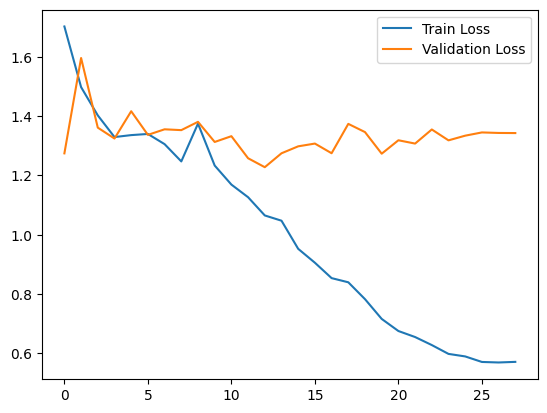

1719
823
Epoch 1/28


Train Loss: 1.6389, Val Loss: 1.5849, Val Accuracy: 0.1434, Val F1 : 0.0414
Validation loss decreased (inf --> -0.041367).  Saving model ...
Updating learning rate to 0.0002
Epoch 2/28


Train Loss: 1.4004, Val Loss: 1.5869, Val Accuracy: 0.1511, Val F1 : 0.0460
Validation loss decreased (-0.041367 --> -0.045971).  Saving model ...
Updating learning rate to 0.0004
Epoch 3/28


Train Loss: 1.3082, Val Loss: 1.5243, Val Accuracy: 0.1730, Val F1 : 0.0597
Validation loss decreased (-0.045971 --> -0.059750).  Saving model ...
Updating learning rate to 0.0006
Epoch 4/28


Train Loss: 1.2654, Val Loss: 1.4787, Val Accuracy: 0.1728, Val F1 : 0.0574
EarlyStopping counter: 1 out of 10
Updating learning rate to 0.0008
Epoch 5/28


Train Loss: 1.2485, Val Loss: 1.4427, Val Accuracy: 0.1620, Val F1 : 0.0811
Validation loss decreased (-0.059750 --> -0.081128).  Saving model ...
Updating learning rate to 0.001
Epoch 6/28


... (19 outputs left out)

Train Loss: 0.4569, Val Loss: 1.6477, Val Accuracy: 0.2694, Val F1 : 0.3940
Validation loss decreased (-0.391286 --> -0.393985).  Saving model ...
Updating learning rate to 4.139434924727359e-05
Epoch 26/28


Train Loss: 0.4566, Val Loss: 1.6639, Val Accuracy: 0.2709, Val F1 : 0.3936
EarlyStopping counter: 1 out of 10
Updating learning rate to 1.8541356326100432e-05
Epoch 27/28


Train Loss: 0.4631, Val Loss: 1.6563, Val Accuracy: 0.2702, Val F1 : 0.3936
EarlyStopping counter: 2 out of 10
Updating learning rate to 4.657026981834622e-06
Epoch 28/28


Train Loss: 0.4443, Val Loss: 1.6541, Val Accuracy: 0.2702, Val F1 : 0.3936
EarlyStopping counter: 3 out of 10
Updating learning rate to 0.0


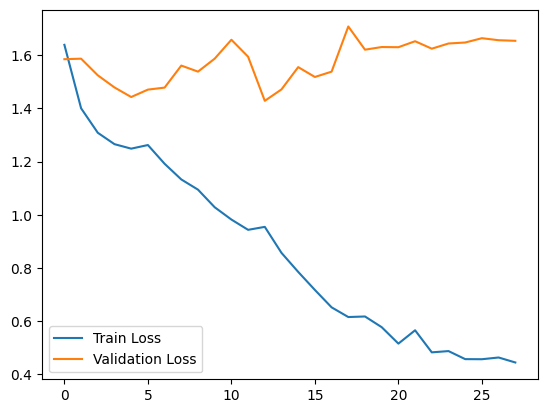

CPU times: user 1h 28min 21s, sys: 1h 18min 51s, total: 2h 47min 12s
Wall time: 2h 51min 8s


In [ ]:
%%time
batch_size = 128
for i in range(len(SUBJECTS)):
    model = TimeSeriesCNN(7501)
    train_model(model, 'TimeSeriesCNN', num_epochs=28, batch_size=batch_size, lr=1e-3, n_fold=i,
                device=device, patience=10, warmup_epochs=5)

## Inference on S004 — fold ensemble

In [ ]:
def predict(model, model_name, batch_size=32, n_fold=0, device='cpu', hard=True):
    _, _, X_test, _, markers = load_data()

    model = model.to(device)
    ckpt = os.path.join(model_name + str(n_fold), 'checkpoint.pth')
    model.load_state_dict(torch.load(ckpt, map_location=device, weights_only=True))

    # labels are unused at inference; zeros keep the Dataset interface happy
    test_dataset = AugmentedDataset(torch.FloatTensor(X_test), torch.zeros(len(X_test), dtype=torch.long), augment=False)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    _, _, outputs = validate(model, test_loader, nn.CrossEntropyLoss(), device)
    return (outputs.argmax(axis=-1) if hard else outputs), markers

In [ ]:
%%time
os.makedirs('submissions', exist_ok=True)
soft_preds = []
for i in range(len(SUBJECTS)):
    probs, markers = predict(model, 'TimeSeriesCNN', batch_size=batch_size, n_fold=i, device=device, hard=False)
    soft_preds.append(probs)
soft_preds = np.mean(soft_preds, axis=0).argmax(axis=-1)
preds = [markers[i] for i in soft_preds]

df = pd.DataFrame({'ID': np.arange(len(preds)), 'Marker': preds})
df.to_csv('submissions/soft_submission.csv', index=False)
df.head()

CPU times: user 10.6 s, sys: 11.4 s, total: 21.9 s
Wall time: 24.9 s


,ID,Marker
0,0,S
1,1,K
2,2,K
3,3,S
4,4,K


In [ ]:
%%time
hard_preds = []
for i in range(len(SUBJECTS)):
    fold_preds, markers = predict(model, 'TimeSeriesCNN', batch_size=batch_size, n_fold=i, device=device, hard=True)
    hard_preds.append(fold_preds)
hard_preds = mode(np.stack(hard_preds, axis=-1), axis=-1).mode
preds = [markers[i] for i in hard_preds]

df = pd.DataFrame({'ID': np.arange(len(preds)), 'Marker': preds})
df.to_csv('submissions/hard_submission.csv', index=False)
df.head()

CPU times: user 11.3 s, sys: 10.6 s, total: 21.9 s
Wall time: 28.8 s


,ID,Marker
0,0,S
1,1,K
2,2,K
3,3,S
4,4,S
